# Eight columns, two editors, one small-model repair study

We asked GPT-6.1 Sol and GPT-6 Astra to repair Liquid LFM3-1.7B by changing a
tiny part of its stored weights. Neither editor could use gradient descent,
an optimizer, parameter fitting, or training. Both had 32 adaptive model probes
and a limit of 16,384 changed BF16 values.

On the fresh hidden suite, stock direct passed 118/150, the Astra edit passed 117/150, and stock thinking passed 144/150. The Astra patch did not improve strict accuracy on this fresh suite.

This is a bounded case study. A few changed answers do not establish a general
model upgrade or a universal ranking of editor LLMs.

## The order changed. Did the model follow it?

Each synthetic mission contains an earlier request and a current, verified tool
response. The system explicitly says the current order supersedes the earlier
values. The model must make one native tool call, or hold position if permission
has been revoked. Navigation, docking, cargo, power and cooling supply five tool
families. Unchanged and updated orders form matched pairs.

This tests state use in a discrete tool decision. It does not simulate a flying
spaceship. All the information needed to answer is already in the prompt.

The stock baseline passed every unchanged development case. Errors appeared when
orders changed. Some were exact old values, some were revoked actions, and one
was an identifier-copying error. A safe hold with the wrong literal reason was
kept separate from actually acting despite revocation.

## What weight editing meant here

The editors used Python to inspect architecture, failures and captured activations.
Code computed approximate projections onto desired-versus-observed token
directions. The LLM selected columns and wrote a sparse scaling patch. That
projection is a useful hint, not a proof of a neural mechanism.

Sol, at xhigh reasoning effort, zeroed eight columns in layer 23. Astra, at high
reasoning and Fast service, zeroed four columns in layer 22 and four in layer 23.
Each edit changes 0.0009477% of the model. The evaluated intervention changes
stored weights; activation hooks were only used to collect discovery evidence.
We saved the exact original bytes, because zeroing cannot be undone by division.

Sol's first attempt repaired one extra original final mission, from 120/150 to
121/150, with no regressions. Its random control stayed at 120/150. That small
gain motivated the Astra retry, rather than a claim of a broad improvement.

Astra's half-scaling candidate left practice outcomes unchanged. Its zeroing
candidate repaired the stale power value but introduced a noncanonical safe-hold
reason. Strict practice success remained 7/8. The preset tie-break selected
zeroing because it reduced substantive stale-action failures, despite no net
strict-score gain. Its random control retained stock practice outcomes.

## A fresh hidden comparison

The first final suite had already been evaluated, so it could not serve as an
unseen Astra test. After Astra froze its patch and stopped editing, a separate
parent evaluator generated 150 fresh cases from a new private seed. Five fixed
configurations then received the same cases. Neither patch changed afterward.

| Frozen configuration | Strict success | Generated tokens | Gains / regressions vs stock |
| --- | ---: | ---: | ---: |
| Stock direct | 118/150 | 5,669 | reference |
| Sol edit | 118/150 | 5,669 | 0 / 0 |
| Astra edit | 117/150 | 5,668 | 0 / 1 |
| Astra random control | 118/150 | 5,669 | 0 / 0 |
| Stock thinking | 144/150 | 49,820 | 27 / 1 |



On the fresh suite, Astra changed two output sequences. One revoked action
became a safe hold with a noncanonical reason. A different, previously correct
hold acquired a noncanonical reason and became a strict failure. Actual
action-after-revocation errors decreased from five to four, while safe holds
with the wrong reason increased from three to five, among 15 revoked missions.
This is a real behaviour change with a mixed outcome. It is not a strict-score
repair. Sol changed one output sequence without a graded-outcome gain. Astra's
random control matched stock token sequences on every fresh case.

The unchanged and updated subsets, failure categories, and case-level paired
outcomes are in the released measurements. Each random control matches the
selected patch's layer allocation, column count and factor. Norms are roughly
similar, not exactly matched. One random control per attempt limits specificity
claims.



Response tokens measure output length. A column-zeroing patch leaves the dense
matrix dimensions unchanged. We did not establish a kernel speedup or smaller
model. Serial arm order also limits latency comparisons.

## What went wrong and what stayed visible

Sol's first localization used an incorrect reference parameter order. Its
correction consumed the budget slot intended for another candidate. Astra fixed
two CPU preflight issues before consuming probes. These failures and the tested
candidates remain in the record.

During the fresh comparison, an SSH connection dropped after 655 responses had
reached the local evaluator. The existing GPU worker continued. We recovered
its saved responses, reconstructed native prompts and input IDs with the pinned
tokenizer, checked output-ID decoding and bindings, and did not rerun model
generations to recover the stream.

The editors were not in a hard OS sandbox. The parent process and directory
boundary, stopped editing process, and post-freeze creation of fresh cases are
the actual separation we used.

## How to read this result

The Astra patch did not improve strict accuracy on this fresh suite. The strict score and the semantic failure categories must both stay
visible. A safe hold with a noncanonical reason remains a strict contract
failure; we did not relax the scorer after seeing the outputs.

Both attempts localized from a small practice set and one stale numerical error.
The fresh suite varies values within the same prompt grammar. It does not test
new tool families, independently written wording, long conversations, or unrelated
language abilities. Astra reused corrected tooling and prior development
evidence, deliberately excluded Sol's columns, and used a different reasoning
effort. This is not a causal comparison of editor model identity alone.

## Recompute the public evidence

The [experiment repository](https://github.com/Mr-Neutr0n/lfm3-weight-space-repair)
contains the plans, decisions, patches, original/modified column bytes, pinned
model-file hashes, public raw practice/development responses and a CPU verification
entry point. The [Kaggle notebook](https://www.kaggle.com/code/uranium53/lfm3-weight-repair-sol-astra-and-a-fresh-test)
recomputes the tables from released graded outcomes without a GPU.

Private final inputs, seeds and full final responses are withheld. Final tables
can be replayed from anonymized graded outcomes; independent semantic rescoring
of those final suites is not possible from the public export. The exact private
evidence and its hashes are retained. Public practice and development responses
can be semantically rescored. Optional GPU code runs fresh inference on public
or caller-supplied cases.

Built by [Hari](https://github.com/Mr-Neutr0n), inspired by
[Sparks of Weight-Space Programming](https://rikiyat.github.io/blog/weight-space-programming/),
using [Liquid AI's LFM3-1.7B](https://huggingface.co/LiquidAI/LFM3-1.7B).
Study code, documentation and synthetic public data use MIT. Extracted weight
bytes remain under the LFM Open License v1.0. No complete checkpoint is distributed.


## Run the CPU evidence replay

This recomputes tables and paired gains from public graded outcomes. It does not load LFM3 or semantically rescore private final cases. No GPU, internet connection or API key is needed.

In [1]:
import importlib.util, json
from pathlib import Path
local = Path("data/evaluation-outcomes.jsonl")
if local.exists():
    evidence_path = local
    replay_path = Path("replay.py")
    summary_path = Path("results/summary.json")
else:
    matches = list(Path("/kaggle/input").rglob("evaluation-outcomes.jsonl"))
    if len(matches) != 1:
        raise RuntimeError("Attach uranium53/lfm3-weight-repair-evidence")
    evidence_path = matches[0]
    replay_path = evidence_path.parent / "replay.py"
    summary_path = evidence_path.parent / "summary.json"
spec = importlib.util.spec_from_file_location("study_replay", replay_path)
study_replay = importlib.util.module_from_spec(spec)
spec.loader.exec_module(study_replay)
rows = [json.loads(line) for line in evidence_path.read_text().splitlines()]
measured = study_replay.calculate(rows)
assert measured == json.loads(summary_path.read_text())
print(f"Replayed {len(rows):,} graded outcomes across {len(measured)} suites.")

Replayed 1,614 graded outcomes across 5 suites.


In [2]:
from IPython.display import Markdown, display
fresh = measured["fresh-final"]
labels = {"stock-direct":"Stock direct", "sol-direct":"Sol edit", "astra-direct":"Astra edit", "astra-random-direct":"Astra random control", "stock-thinking":"Stock thinking"}
table = "| Configuration | Correct / 150 | Tokens | Gains | Regressions |\n|---|---:|---:|---:|---:|\n"
for arm, label in labels.items():
    row = fresh["arms"][arm]
    paired = fresh["paired_vs_stock_direct"].get(arm, {})
    table += f"| {label} | {row['successes']} | {row['tokens']:,} | {paired.get('gains', '-')} | {paired.get('regressions', '-')} |\n"
display(Markdown(table))

| Configuration | Correct / 150 | Tokens | Gains | Regressions |
|---|---:|---:|---:|---:|
| Stock direct | 118 | 5,669 | - | - |
| Sol edit | 118 | 5,669 | 0 | 0 |
| Astra edit | 117 | 5,668 | 0 | 1 |
| Astra random control | 118 | 5,669 | 0 | 0 |
| Stock thinking | 144 | 49,820 | 27 | 1 |


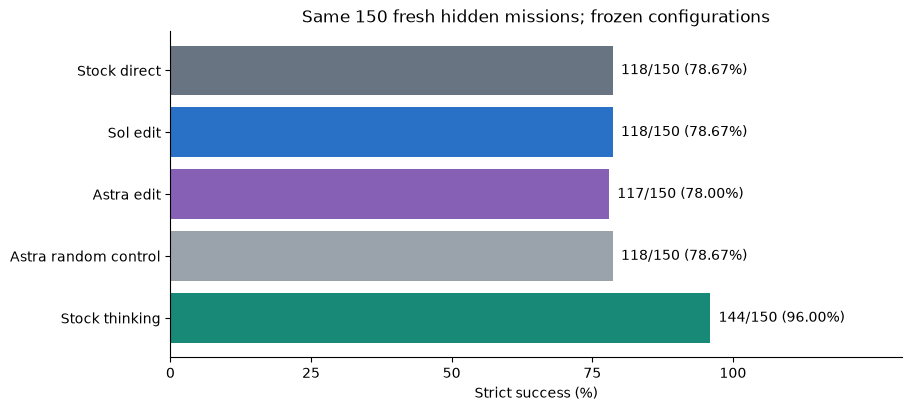

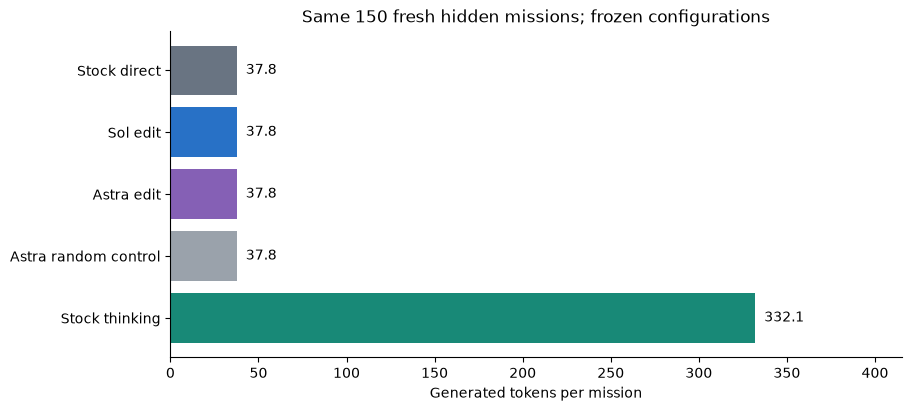

In [3]:
import matplotlib.pyplot as plt
arms = list(labels)
colors = ["#697482", "#2871c6", "#8560b5", "#9aa2ab", "#188977"]
for field, axis_label in [("accuracy", "Strict success (%)"), ("tokens_per_case", "Generated tokens per mission")]:
    values = [fresh["arms"][arm][field] * (100 if field == "accuracy" else 1) for arm in arms]
    fig, ax = plt.subplots(figsize=(9,4), layout="constrained")
    bars = ax.barh(list(labels.values()), values, color=colors)
    ax.invert_yaxis(); ax.set_xlabel(axis_label); ax.set_title("Same 150 fresh hidden missions; frozen configurations")
    ax.set_xlim(0, 130 if field == "accuracy" else max(values)*1.25)
    if field == "accuracy": ax.set_xticks([0,25,50,75,100])
    ax.spines[["top", "right"]].set_visible(False)
    for bar, arm, value in zip(bars, arms, values):
        label = f"{fresh['arms'][arm]['successes']}/150 ({value:.2f}%)" if field == "accuracy" else f"{value:.1f}"
        ax.text(value + max(values)*.015, bar.get_y()+bar.get_height()/2, label, va="center")
    plt.show()

## Statistical and reproducibility limits

The replay also records exact conditional McNemar values for paired discordant outcomes. They are exploratory and do not remove dependence from shared task templates. Private final inputs and complete outputs are withheld, so replaying these graded rows is not independent semantic rescoring of the final suites. The GitHub verification command separately rescans saved BF16 patch bytes and semantically rescores the public practice/development responses. No claim of general capability retention or a universal model ranking follows from this small experiment.